# Berlin Airbnb Market Analysis & Price Prediction
**Author:** Sonu Phogat · **Data:** [Inside Airbnb](https://insideairbnb.com/get-the-data/) Berlin snapshot, 19 September 2026

### Business questions
1. Where in Berlin are listings most expensive, and how large is each district's market?
2. How is the market split between room types and between small and professional hosts?
3. How do short-term listings comply with Berlin's registration rules?
4. Which listing characteristics drive the nightly price, and can we predict it?

> Run `python src/download_data.py && python src/clean.py` first (or `make all`).

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
BRAND, BLUE, GREEN = "#ff5a5f", "#2f6fed", "#12a150"

raw = pd.read_csv(ROOT / "data/raw/listings.csv.gz", low_memory=False)
df = pd.read_csv(ROOT / "data/processed/listings_clean.csv")
print(f"Raw listings: {len(raw):,} | with a valid price (€15–1,000): {len(df):,}")
df.head()

Raw listings: 12,376 | with a valid price (€15–1,000): 8,127


,id,district,neighbourhood,latitude,longitude,room_type,property_type,accommodates,bedrooms,beds,...,superhost,host_id,host_listings,est_occupancy_nights,est_revenue,amenities_count,license_status,price_per_guest,host_type,short_term
0,1733333348320050763,Charlottenburg-Wilmersdorf,Grunewald,52.483084,13.284662,Entire home/apt,Entire rental unit,2,1.0,2.0,...,False,1729156025960279337,1,13,1261.0,12,Registration number,48.50,Single-listing host,True
1,811527740012470418,Charlottenburg-Wilmersdorf,Grunewald,52.492120,13.290770,Entire home/apt,Entire rental unit,2,1.0,1.0,...,False,366280303,1,0,0.0,7,Business / host disclosure,34.80,Single-listing host,True
2,638045311043310955,Neukölln,Rixdorf,52.471619,13.443734,Entire home/apt,Entire rental unit,4,2.0,2.0,...,False,37827150,1,0,0.0,6,Registration number,54.75,Single-listing host,True
3,2384606,Tempelhof-Schöneberg,Schöneberg-Süd,52.485950,13.364830,Private room,Private room in rental unit,4,1.0,2.0,...,False,12163724,1,0,0.0,6,Registration number,16.42,Single-listing host,True
4,1182478073367462638,Tempelhof-Schöneberg,Schöneberg-Süd,52.487500,13.359320,Private room,Private room in rental unit,2,1.0,1.0,...,False,43474796,1,0,0.0,2,Registration number,37.00,Single-listing host,True


## 1. Data quality
Inside Airbnb only shows a price for listings that are currently bookable, so listings without a price are inactive and are excluded. Prices outside €15–1,000 are treated as placeholders or errors. Note: the raw file shows a `$` sign, but Berlin prices are in EUR.

In [2]:
missing = raw[["price", "bedrooms", "review_scores_rating", "license", "minimum_nights"]].isna().mean().mul(100).round(1)
print("Missing values in raw data (%):"); print(missing.to_string())
df["price"].describe().round(1)

Missing values in raw data (%):
price                   34.1
bedrooms                 0.1
review_scores_rating    18.1
license                 32.6
minimum_nights           1.2


count    8127.0
mean      161.3
std       119.7
min        15.0
25%        81.0
50%       129.0
75%       201.9
max      1000.0
Name: price, dtype: float64

## 2. Prices across Berlin's districts

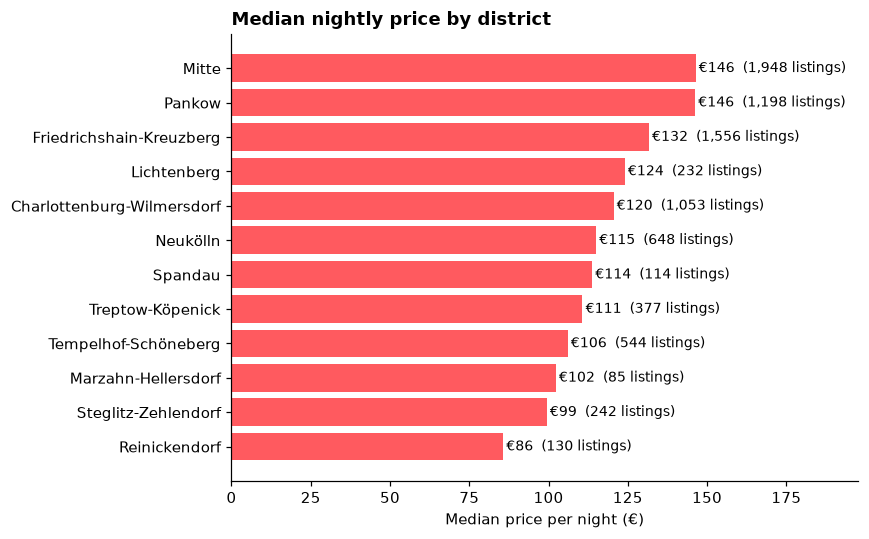

,listings,median_price,pct_entire
district,,,
Mitte,1948,146.4,74.9
Pankow,1198,146.2,79.9
Friedrichshain-Kreuzberg,1556,131.7,71.0
Lichtenberg,232,124.0,71.6
Charlottenburg-Wilmersdorf,1053,120.5,68.3
Neukölln,648,115.0,63.6
Spandau,114,113.8,58.8
Treptow-Köpenick,377,110.7,76.1
Tempelhof-Schöneberg,544,106.0,70.4


In [3]:
by_district = (df.groupby("district")
                .agg(listings=("id", "size"), median_price=("price", "median"), pct_entire=("room_type", lambda s: (s == "Entire home/apt").mean() * 100))
                .sort_values("median_price"))
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(by_district.index, by_district["median_price"], color=BRAND)
for i, (v, n) in enumerate(zip(by_district["median_price"], by_district["listings"])):
    ax.text(v + 1, i, f"€{v:.0f}  ({n:,} listings)", va="center", fontsize=9)
ax.set_xlabel("Median price per night (€)"); ax.set_title("Median nightly price by district", loc="left", fontweight="bold")
ax.set_xlim(0, by_district["median_price"].max() * 1.35)
plt.tight_layout(); plt.savefig(FIG / "price_by_district.png", bbox_inches="tight"); plt.show()
by_district.sort_values("median_price", ascending=False).round(1)

**Insight:** The central districts **Mitte, Pankow (Prenzlauer Berg) and Friedrichshain-Kreuzberg** are the most expensive and together hold over half of all listings. The outer districts such as Reinickendorf and Steglitz-Zehlendorf are 30–40% cheaper.

## 3. Room types and price distribution

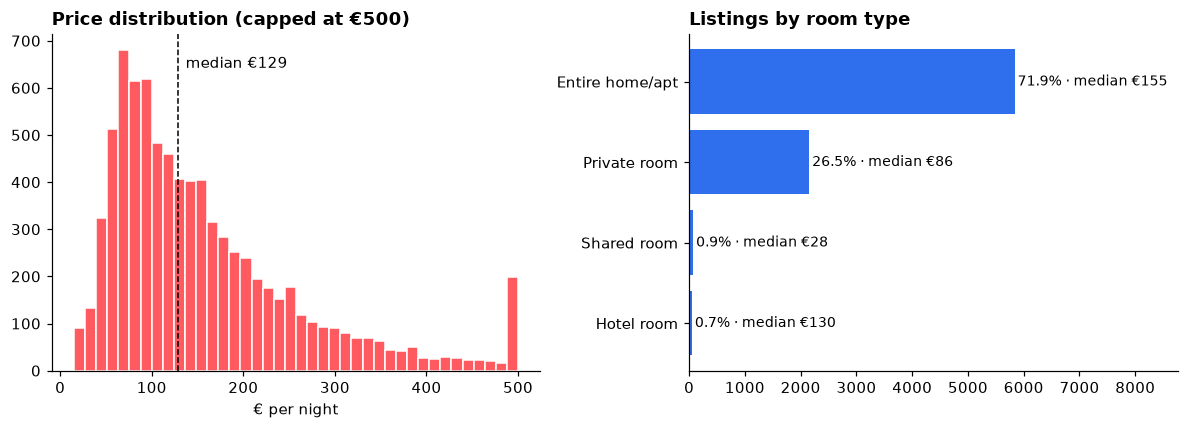

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df["price"].clip(upper=500), bins=40, color=BRAND, edgecolor="white")
axes[0].axvline(df["price"].median(), color="black", ls="--", lw=1); axes[0].text(df["price"].median() + 8, axes[0].get_ylim()[1] * .9, f"median €{df['price'].median():.0f}")
axes[0].set_title("Price distribution (capped at €500)", loc="left", fontweight="bold"); axes[0].set_xlabel("€ per night")
rooms = df.groupby("room_type")["price"].agg(["count", "median"]).sort_values("count")
axes[1].barh(rooms.index, rooms["count"], color=BLUE)
for i, (c, m) in enumerate(zip(rooms["count"], rooms["median"])):
    axes[1].text(c + 50, i, f"{c / len(df):.1%} · median €{m:.0f}", va="center", fontsize=9)
axes[1].set_xlim(0, rooms["count"].max() * 1.5); axes[1].set_title("Listings by room type", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "price_distribution_room_types.png", bbox_inches="tight"); plt.show()

**Insight:** Prices are strongly right-skewed (a long tail of luxury listings), so the model predicts **log(price)**. About **72%** of listings are entire homes, with a median price about €70 higher per night than private rooms (€155 vs €86).

## 4. Who are the hosts? Market concentration

59.5% of listings belong to hosts with more than one listing
Top 1% of hosts (44) control 15.8% of listings
Top 10 hosts control 7.6% of listings (largest host: 117 listings)


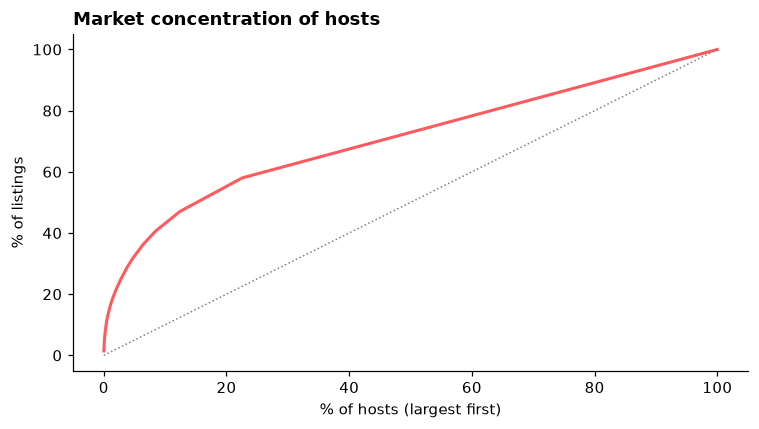

In [5]:
host_sizes = df.groupby("host_id").size().sort_values(ascending=False)
cum_share = host_sizes.cumsum() / host_sizes.sum() * 100
multi = (df["host_type"] == "Multi-listing host").mean() * 100
print(f"{multi:.1f}% of listings belong to hosts with more than one listing")
print(f"Top 1% of hosts ({int(len(host_sizes) * .01)}) control {cum_share.iloc[int(len(host_sizes) * .01) - 1]:.1f}% of listings")
print(f"Top 10 hosts control {cum_share.iloc[9]:.1f}% of listings (largest host: {host_sizes.iloc[0]} listings)")
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(cum_share) + 1) / len(cum_share) * 100, cum_share.values, color=BRAND, lw=2)
ax.plot([0, 100], [0, 100], color="grey", ls=":", lw=1)
ax.set_xlabel("% of hosts (largest first)"); ax.set_ylabel("% of listings"); ax.set_title("Market concentration of hosts", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "host_concentration.png", bbox_inches="tight"); plt.show()

**Insight:** Most listings are run by **multi-listing (often professional) hosts**, not by people renting out their own home now and then. This matters for policy discussions about housing supply.

## 5. Regulation: registration numbers
Since the *Zweckentfremdungsverbot*, renting out an apartment in Berlin for **fewer than 30 nights** requires a registration number (format `01/Z/AZ/012345-24`). Businesses must disclose their details. I grouped the free-text `license` field into categories.

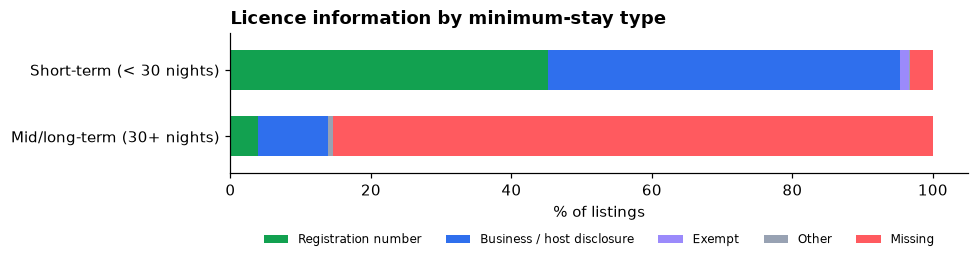

license_status,Registration number,Business / host disclosure,Exempt,Other,Missing
row_0,,,,,
Mid/long-term (30+ nights),3.9,10.0,0.0,0.7,85.4
Short-term (< 30 nights),45.2,50.2,1.2,0.2,3.2


In [6]:
lic = (pd.crosstab(np.where(df["short_term"], "Short-term (< 30 nights)", "Mid/long-term (30+ nights)"), df["license_status"], normalize="index") * 100)
order = ["Registration number", "Business / host disclosure", "Exempt", "Other", "Missing"]
lic = lic[[c for c in order if c in lic.columns]]
colors = {"Registration number": GREEN, "Business / host disclosure": BLUE, "Exempt": "#9b8afb", "Other": "#98a2b3", "Missing": BRAND}
ax = lic.plot(kind="barh", stacked=True, figsize=(9, 2.8), color=[colors[c] for c in lic.columns], width=.6)
ax.set_xlabel("% of listings"); ax.set_ylabel(""); ax.legend(ncol=5, fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.35), frameon=False)
ax.set_title("Licence information by minimum-stay type", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "licence_compliance.png", bbox_inches="tight"); plt.show()
lic.round(1)

**Insight:** Among short-term listings only about **3%** show no registration or disclosure. Listings without a number almost all require **30+ night stays**, which falls outside the short-term rules. Many hosts appear to have switched to mid-term rentals, so Berlin's market now has a large share of furnished mid-term apartments.

## 6. SQL analysis
The same questions are answered in SQL (`sql/business_questions.sql`) on a SQLite copy of the data. Full results are in `reports/sql_results.md`.

In [7]:
import sqlite3
conn = sqlite3.connect(":memory:"); df.to_sql("listings", conn, index=False)
pd.read_sql_query('''
SELECT CASE WHEN superhost = 1 THEN 'Superhost' ELSE 'Regular host' END AS host_status,
       COUNT(*) AS listings, ROUND(AVG(price)) AS avg_price,
       ROUND(AVG(review_score), 2) AS avg_rating, ROUND(AVG(est_occupancy_nights)) AS avg_booked_nights
FROM listings GROUP BY superhost''', conn)

,host_status,listings,avg_price,avg_rating,avg_booked_nights
0,Regular host,5208,149.0,4.66,93.0
1,Superhost,2919,183.0,4.86,178.0


**Insight:** Superhosts charge more, get higher ratings, **and** are booked roughly twice as many nights per year. Quality pays off.

## 7. Predicting the nightly price
**Features:** only things a host could enter in a form (district, room type, guests, bedrooms, bathrooms, shared bath, minimum stay, number of amenities, review score, superhost). The same model then powers the live price estimator.
**Setup:** 80/20 train/test split, 5-fold cross-validation on the training set, target = log(price). Code in `src/train_model.py`.

In [8]:
results = pd.read_csv(ROOT / "reports/model_comparison.csv")
results

,model,cv_r2_log,test_r2_log,test_mae_eur,test_median_ae_eur
0,Baseline (median),-0.001,-0.000,78.6,54.2
1,Ridge regression,0.617,0.617,50.6,29.4
2,Random forest,0.650,0.649,47.7,27.5
3,Gradient boosting,0.661,0.662,47.0,27.1


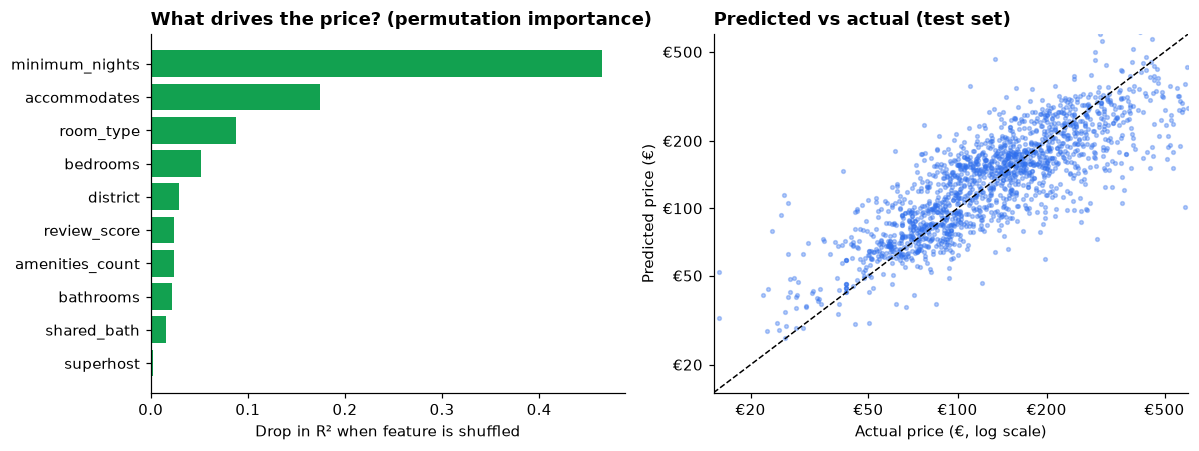

In [9]:
imp = pd.read_csv(ROOT / "reports/feature_importance.csv").sort_values("importance")
preds = pd.read_csv(ROOT / "reports/test_predictions.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].barh(imp["feature"], imp["importance"], color=GREEN)
axes[0].set_title("What drives the price? (permutation importance)", loc="left", fontweight="bold"); axes[0].set_xlabel("Drop in R² when feature is shuffled")
axes[1].scatter(preds["actual"], preds["predicted"], s=6, alpha=.35, color=BLUE)
lim = [15, 600]; axes[1].plot(lim, lim, color="black", lw=1, ls="--")
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_xlim(lim); axes[1].set_ylim(lim)
ticks = [20, 50, 100, 200, 500]
for axis in (axes[1].xaxis, axes[1].yaxis):
    axis.set_major_locator(plt.FixedLocator(ticks)); axis.set_minor_locator(plt.NullLocator())
    axis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"€{v:.0f}"))
axes[1].set_xlabel("Actual price (€, log scale)"); axes[1].set_ylabel("Predicted price (€)"); axes[1].set_title("Predicted vs actual (test set)", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "model_results.png", bbox_inches="tight"); plt.show()

In [10]:
best = results.set_index("model").loc["Gradient boosting"]
print(f"Gradient boosting: test R² (log) = {best.test_r2_log:.3f}, MAE = €{best.test_mae_eur:.0f}, median error = €{best.test_median_ae_eur:.0f}")
print(f"Improvement over baseline MAE: {(1 - best.test_mae_eur / results.set_index('model').loc['Baseline (median)', 'test_mae_eur']):.0%}")

Gradient boosting: test R² (log) = 0.662, MAE = €47, median error = €27
Improvement over baseline MAE: 40%


**Insight:**
- Gradient boosting performs best (R² ≈ 0.66 on log price; **median error about €27**), cutting the baseline error by about 40%.
- **Minimum stay is the strongest driver**: mid-term listings (30+ nights) are much cheaper per night, which links back to the regulation finding.
- Size (guests, bedrooms) and room type come next. Location matters, but less than you might expect at district level.
- **Limitations:** no photos, description text, exact location or seasonality, which together probably explain much of the remaining error.

## 8. Conclusions & recommendations
| For | Recommendation |
|---|---|
| **Hosts** | Size and room type set the price level; becoming a superhost goes with much higher occupancy. |
| **Guests** | Outer districts (Reinickendorf, Steglitz-Zehlendorf, Treptow-Köpenick) are 25–40% cheaper. |
| **City / policy** | The registration rule seems to be followed by short-term listings, but it has pushed supply towards 30+ night furnished rentals, which the current rules don't cover. |

**Next steps:** add text features from listing descriptions (NLP), use exact coordinates (distance to the centre), and add seasonal calendar data.